<small>Dataset: Mall_Customers.csv</small>

# Q27. Mall Customers K Means

Discover groups using K-Means, choose K from an elbow plot and explain the group profiles.


## Question from Classroom

Mall Customer clustering/classification 
Problem statement: Identify distinct customer groups using the Mall Customers dataset. 
Tasks to be performed: 
1. Load the dataset containing CustomerID, Gender, Age, Annual Income (k$) and 
Spending Score (1-100). 
2. Select annual income and spending score for clustering. 
3. Standardize the features and use the elbow method to select K. 
4. Fit the K-Means algorithm. 
5. Plot the clusters with their centroids. 
6. Calculate the number of customers in each cluster. 
7. Visualize the clusters


## Understand before coding

Select features -> inspect/impute -> scale -> fit K=2..8 -> inspect elbow -> choose K -> plot and describe centroids/counts.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load the dataset containing CustomerID, Gender, Age, Annual Income (k$) and Spending Score (1-100).

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
df=pd.read_csv("data/Mall_Customers.csv")
print(df.head())


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


## Task 2. Select annual income and spending score for clustering.

This block implements the task above. Variables from earlier blocks are reused.


In [2]:
features=["Annual Income (k$)","Spending Score (1-100)"]
X=df[features]


## Task 3. Standardize the features and use the elbow method to select K.

This block implements the task above. Variables from earlier blocks are reused.


 K    Inertia
 2 269.691012
 3 157.704008
 4 108.921317
 5  65.568408
 6  55.057348
 7  44.864756
 8  37.228188


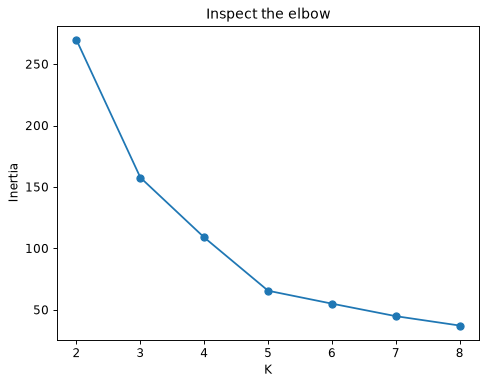

In [3]:
imputer=SimpleImputer(strategy="median")
clean=imputer.fit_transform(X)
scaler=StandardScaler()
scaled=scaler.fit_transform(clean)

candidate_k=list(range(2,9))
inertias=[]
for k in candidate_k:
    trial=KMeans(n_clusters=k,n_init=10,random_state=42).fit(scaled)
    inertias.append(trial.inertia_)
print(pd.DataFrame({"K":candidate_k,"Inertia":inertias}).to_string(index=False))
plt.plot(candidate_k,inertias,"o-")
plt.xlabel("K");plt.ylabel("Inertia");plt.title("Inspect the elbow");plt.show()


## Task 4. Fit the K-Means algorithm.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
k=int(input("Choose K after inspecting the elbow [5]: ") or "5")
if not 2<=k<=8:raise ValueError("Choose K from 2 to 8 for this practice example")
model=KMeans(n_clusters=k,n_init=10,random_state=42).fit(scaled)


Choose K after inspecting the elbow [5]: 


## Task 5. Plot the clusters with their centroids.

This block implements the task above. Variables from earlier blocks are reused.


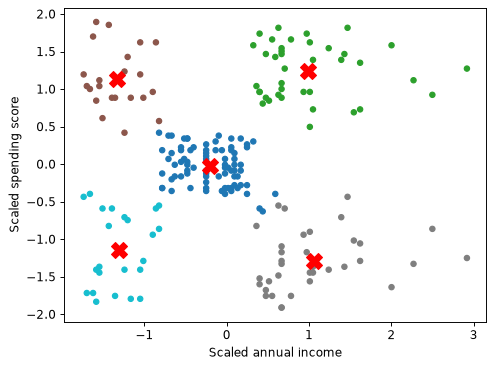

In [5]:
plt.scatter(scaled[:,0],scaled[:,1],c=model.labels_,cmap="tab10",s=20)
plt.scatter(model.cluster_centers_[:,0],model.cluster_centers_[:,1],marker="X",c="red",s=180)
plt.xlabel("Scaled annual income");plt.ylabel("Scaled spending score");plt.show()


## Task 6. Calculate the number of customers in each cluster.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
profile=pd.DataFrame(clean,columns=features)
profile["Cluster"]=model.labels_
print("Record counts:\n",profile["Cluster"].value_counts().sort_index())
print("Cluster means in original units:\n",profile.groupby("Cluster").mean().round(2))
print("Centroids in original units:\n",pd.DataFrame(scaler.inverse_transform(model.cluster_centers_),columns=features).round(2))
print("Cluster IDs are arbitrary. Describe groups using their actual feature means.")


Record counts:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Cluster means in original units:
          Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91
Centroids in original units:
    Annual Income (k$)  Spending Score (1-100)
0               55.30                   49.52
1               86.54                   82.13
2               25.73                   79.36
3               88.20                   17.11
4               26.30                   20.91
Cluster IDs are arbitrary. Describe groups using their actual feature means.


## Task 7. Visualize the clusters

This block implements the task above. Variables from earlier blocks are reused.


The plot shows customer groups and red centroid markers.


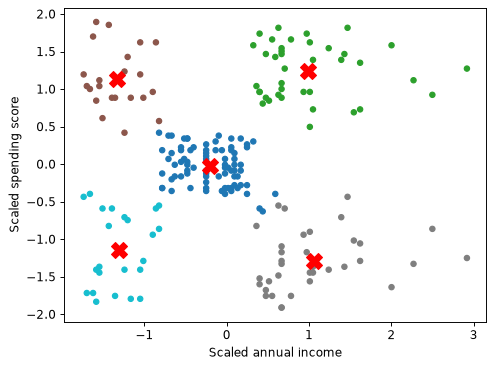

In [7]:
plt.scatter(scaled[:,0],scaled[:,1],c=model.labels_,cmap="tab10",s=20)
plt.scatter(model.cluster_centers_[:,0],model.cluster_centers_[:,1],marker="X",c="red",s=180)
plt.xlabel("Scaled annual income");plt.ylabel("Scaled spending score");plt.show()
print("The plot shows customer groups and red centroid markers.")


## Viva preparation guide

**1. What is clustering?**

Unsupervised grouping by feature similarity. No known class label y is used to fit K-Means.

**2. What does K-Means minimize?**

Inertia: the sum of squared distances from each standardized record to its assigned centroid.

**3. What are the algorithm steps?**

Initialize K centroids, assign every point to its closest centroid, recompute centroid means and repeat until convergence or the iteration limit.

**4. Why standardize?**

Distance depends on feature units. Scaling balances the influence of the chosen features.

**5. What is the elbow method?**

Plot inertia against K and inspect where additional clusters give much smaller improvements. The elbow can be ambiguous; there may be no unique obvious K.

**6. Why does inertia usually decrease with K?**

More centroids allow points to be represented more closely. The lowest inertia alone would encourage unnecessarily many clusters.

**7. What are n_init and random_state?**

n_init repeats centroid initialization and keeps a good solution; random_state makes randomized choices reproducible.

**8. Is KNN the same as K-Means?**

No. KNN uses labeled neighbours to predict classes. K-Means discovers unlabeled groups around centroids.

**9. How should clusters be interpreted?**

Read their original-unit mean profiles and counts. Cluster number 0 has no inherent ranking or real-world meaning.

**10. What are limitations?**

Sensitivity to scale, initialization and outliers; preference for approximately spherical groups; a required K; no guarantee that statistical groups correspond to meaningful categories.

**11. What is the complexity?**

Roughly O(n*K*p*iterations) per initialization, for n points and p features. Multiple n_init runs multiply fitting work.

**12. Which features are selected?**

Annual Income (k$) and Spending Score (1-100). CustomerID is excluded.

**13. Why no train/test split here?**

This is descriptive segmentation of the provided dataset, not held-out prediction accuracy. If evaluating assignment to future customers, fit preprocessing and centroids on a separate training set.

**14. Why show original-unit profiles?**

Scaled centroids are hard to interpret directly. inverse_transform returns units such as income and spending score.


### Task-to-code map

- **Block 1:** Load the dataset containing CustomerID, Gender, Age, Annual Income (k$) and Spending Score (1-100).
- **Block 2:** Select annual income and spending score for clustering.
- **Block 3:** Standardize the features and use the elbow method to select K.
- **Block 4:** Fit the K-Means algorithm.
- **Block 5:** Plot the clusters with their centroids.
- **Block 6:** Calculate the number of customers in each cluster.
- **Block 7:** Visualize the clusters
